# Chapter 2

Python version of the R code for Chapter 2 of *In All Likelihood* (Pawitan, 2001).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats, optimize, special

from helpers import li, num_hessian

## Figure 2.1 (`FIG2-1.R`)

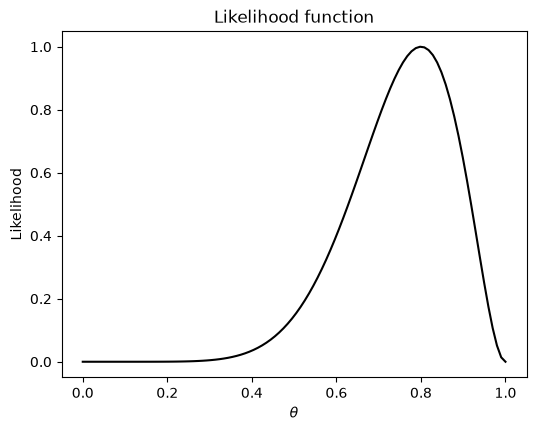

In [2]:
x, n = 8, 10

theta = np.linspace(0, 1, 100)
like = stats.binom.pmf(8, 10, theta)
like = like / like.max()

fig, ax = plt.subplots(figsize=(6, 4.5))
ax.plot(theta, like, "k-")
ax.set_xlabel(r"$\theta$")
ax.set_ylabel("Likelihood")
ax.set_title("Likelihood function")
plt.show()

It is also possible to plot the likelihood as a function, but we need to know
the MLE in advance:

```python
like = lambda theta: stats.binom.pmf(x, n, theta) / stats.binom.pmf(x, n, x / n)
```

## Figure 2.2 (`FIG2-2.R`)

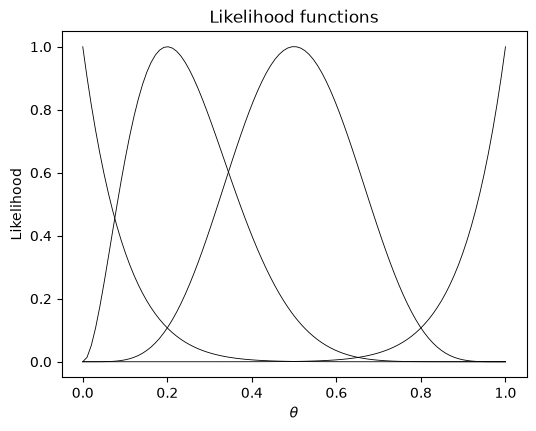

In [3]:
x, n = 2, 10

theta = np.linspace(0, 1, 100)
like = stats.binom.pmf(x, 10, theta)
like = like / like.max()

fig, ax = plt.subplots(figsize=(6, 4.5))
ax.plot(theta, like, "k-", lw=0.6)
ax.set_title("Likelihood functions")

for x in [0, 5, 10]:
    like = stats.binom.pmf(x, 10, theta)
    like = like / like.max()
    ax.plot(theta, like, "k-", lw=0.6)

ax.set_xlabel(r"$\theta$")
ax.set_ylabel("Likelihood")
plt.show()

## Example 2.1 (`EX2-1.R`)

(a) Censored data.

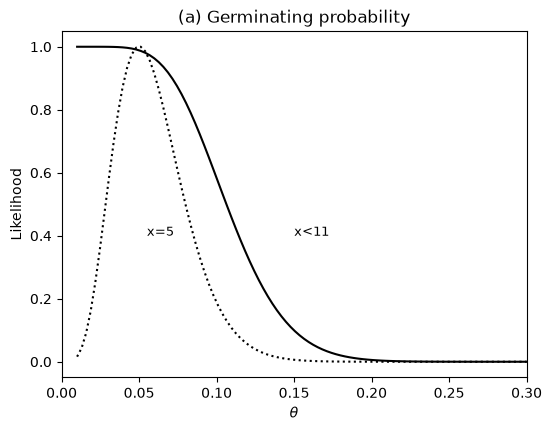

In [4]:
theta = np.linspace(.01, .3, 100)

like = stats.binom.cdf(10, 100, theta)
like1 = like / like.max()

like = stats.binom.pmf(5, 100, theta)
like2 = like / like.max()

fig, ax = plt.subplots(figsize=(6, 4.5))
ax.plot(theta, like1, "k-")
ax.plot(theta, like2, "k:", lw=1.5)
ax.text(.15, .4, "x<11", fontsize=9)
ax.text(.055, .4, "x=5", fontsize=9)
ax.set_xlim(0, .3)
ax.set_xlabel(r"$\theta$")
ax.set_ylabel("Likelihood")
ax.set_title("(a) Germinating probability")
plt.show()

## Example 2.2 (`EX2-2.R`)

(b) Badgers.

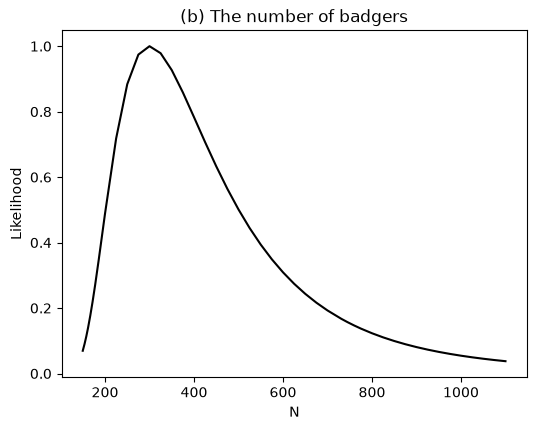

In [5]:
n = 25
k = 60
n1 = 5

NN = np.concatenate([np.arange(150, 201), np.arange(200, 726, 25),
                     np.arange(725, 776), np.arange(775, 1101, 25)])
N = NN.astype(float)
loglik = (special.gammaln(N - n + 1) - special.gammaln(N - n - k + n1 + 1)
          - special.gammaln(N + 1) + special.gammaln(N - k + 1))
like = np.exp(loglik - loglik.max())

fig, ax = plt.subplots(figsize=(6, 4.5))
ax.plot(NN, like, "k-")
ax.set_xlabel("N")
ax.set_ylabel("Likelihood")
ax.set_title("(b) The number of badgers")
plt.show()

## Example 2.3 (`EX2-3.R`)

(c) Negative binomial.

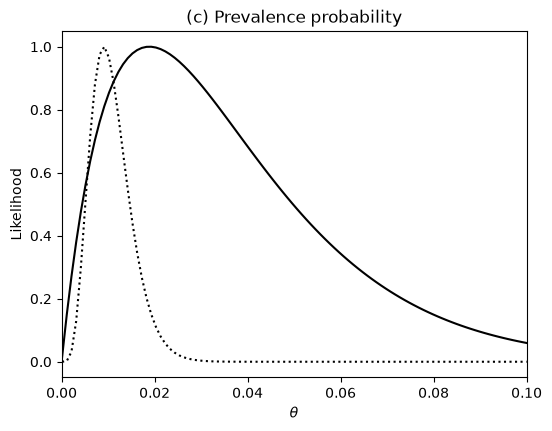

In [6]:
theta = np.linspace(.0001, .1, 100)
like = stats.binom.pmf(1, 53, theta)
like1 = like / like.max()

like = stats.binom.pmf(5, 552, theta)
like2 = like / like.max()

fig, ax = plt.subplots(figsize=(6, 4.5))
ax.plot(theta, like1, "k-")
ax.plot(theta, like2, "k:", lw=1.5)
ax.set_xlim(0, .1)
ax.set_xlabel(r"$\theta$")
ax.set_ylabel("Likelihood")
ax.set_title("(c) Prevalence probability")
plt.show()

## Example 2.4 (`EX2-4.R`)

(d) Normal example.

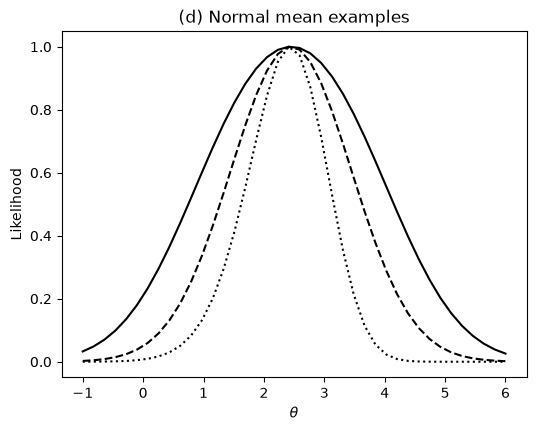

In [7]:
theta = np.linspace(-1, 6, 40)

like = stats.norm.cdf(4, theta) - stats.norm.cdf(0.9, theta)
like = like / like.max()

fig, ax = plt.subplots(figsize=(6, 4.5))
ax.plot(theta, like, "k-")

like = stats.norm.pdf(2.45, theta)
like = like / like.max()
ax.plot(theta, like, "k--")

n = 5
xn = 3.5
llike = np.log(stats.norm.pdf(xn, loc=theta)) + (n - 1) * np.log(stats.norm.cdf(xn, loc=theta))
like = np.exp(llike - llike.max())
ax.plot(theta, like, "k:", lw=1.5)

ax.set_xlabel(r"$\theta$")
ax.set_ylabel("Likelihood")
ax.set_title("(d) Normal mean examples")
plt.show()

## Example 2.7 (`EX2-7.R`)

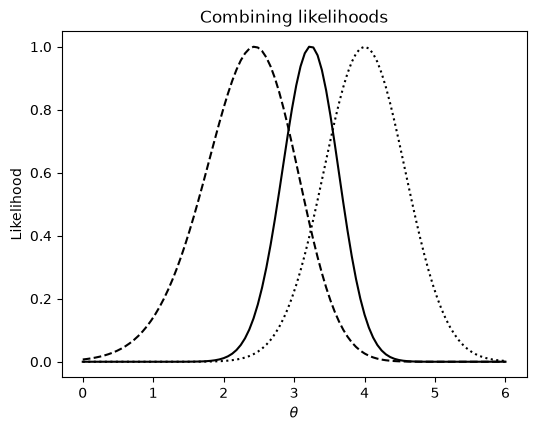

In [8]:
theta = np.linspace(0, 6, 100)

# sample 1: data max=3.5 from x1 to x5 iid N(theta,1)
n = 5
x = 3.5
loglik1 = (n - 1) * np.log(stats.norm.cdf(x - theta)) + np.log(stats.norm.pdf(x - theta))
loglik1 = loglik1 - loglik1.max()
lik1 = np.exp(loglik1)

# sample 2: ybar from y1 to y3 iid N(theta,1)
n = 3
ybar = 4
loglik2 = np.log(stats.norm.pdf(ybar, loc=theta, scale=np.sqrt(1 / n)))
loglik2 = loglik2 - loglik2.max()
lik2 = np.exp(loglik2)

# combined sample
loglik = loglik1 + loglik2
loglik = loglik - loglik.max()
lik = np.exp(loglik)

fig, ax = plt.subplots(figsize=(6, 4.5))
ax.plot(theta, lik, "k-")
ax.plot(theta, lik1, "k--")
ax.plot(theta, lik2, "k:")
ax.set_xlabel(r"$\theta$")
ax.set_ylabel("Likelihood")
ax.set_title("Combining likelihoods")
plt.show()

## Example 2.11 (`EX2-11.R`)

In [9]:
n = 5
xn = 3.5


def llike(theta):
    """Minus log-likelihood."""
    return (-np.log(stats.norm.pdf(xn, loc=theta))
            - (n - 1) * np.log(stats.norm.cdf(xn, loc=theta)))


# Nonlinear optimisation, starting at 3.5.
# The estimate is out.x and the Fisher information is the Hessian.
out = optimize.minimize(lambda p: llike(p[0]), [3.5])
print("minimum  =", out.fun)
print("estimate =", out.x)
print("hessian  =", num_hessian(lambda p: llike(p[0]), out.x))

minimum  = 2.1053505670523385
estimate = [2.43848403]
hessian  = [[2.40852132]]


## Example 2.12 (`EX2-12.R`)

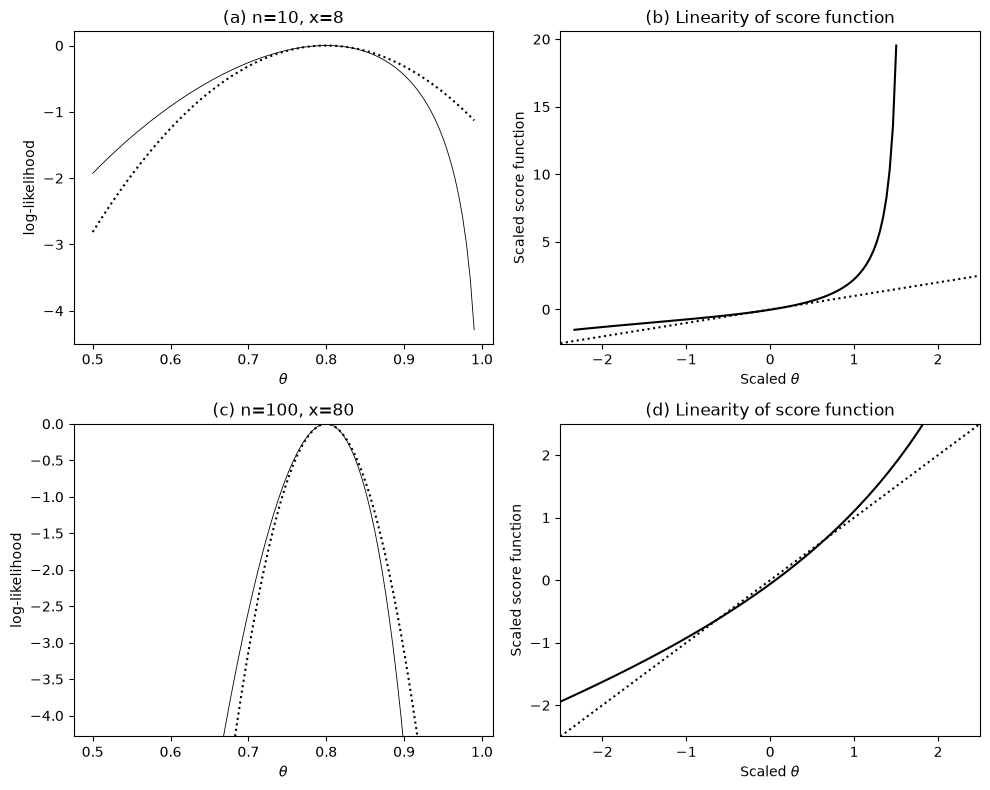

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(10, 8))
axes = axes.ravel()

x, n = 8, 10
theta = np.linspace(0.5, .99, 100)

like = stats.binom.pmf(8, 10, theta)
like1 = like / like.max()
ll = np.log(like1)

that = x / n
ihat = n / that / (1 - that)
la = -ihat / 2 * (theta - that) ** 2
ra = (ll.min(), ll.max())

ax = axes[0]
ax.plot(theta, ll, "k-", lw=0.6)
ax.plot(theta, la, "k:", lw=1.5)
ax.set_xlabel(r"$\theta$")
ax.set_ylabel("log-likelihood")
ax.set_title("(a) n=10, x=8")

sco = -1 / np.sqrt(ihat) * np.diff(ll) / np.diff(theta)
the = np.sqrt(ihat) * (theta[1:] - that)

ax = axes[1]
ax.plot(the, sco, "k-")
ax.axline((0, 0), slope=1, color="k", ls=":", lw=1.5)
ax.set_xlim(-2.5, 2.5)
ax.set_xlabel(r"Scaled $\theta$")
ax.set_ylabel("Scaled score function")
ax.set_title("(b) Linearity of score function")

x, n = 80, 100
theta = np.linspace(0.5, .99, 100)

ll = x * np.log(theta) + (n - x) * np.log(1 - theta)
ll = ll - ll.max()

that = x / n
ihat = n / that / (1 - that)
la = -ihat / 2 * (theta - that) ** 2

ax = axes[2]
ax.plot(theta, ll, "k-", lw=0.6)
ax.plot(theta, la, "k:", lw=1.5)
ax.set_ylim(ra)
ax.set_xlabel(r"$\theta$")
ax.set_ylabel("log-likelihood")
ax.set_title("(c) n=100, x=80")

sco = -1 / np.sqrt(ihat) * np.diff(ll) / np.diff(theta)
the = np.sqrt(ihat) * (theta[1:] - that)

ax = axes[3]
ax.plot(the, sco, "k-")
ax.axline((0, 0), slope=1, color="k", ls=":", lw=1.5)
ax.set_xlim(-2.5, 2.5)
ax.set_ylim(-2.5, 2.5)
ax.set_xlabel(r"Scaled $\theta$")
ax.set_ylabel("Scaled score function")
ax.set_title("(d) Linearity of score function")

fig.tight_layout()
plt.show()

## Example 2.13 (`EX2-13.R`)

`li()` computes a likelihood interval using some interpolation.

cutoff= 0.04 Interval= [0.40774369 0.98288015]
cutoff= 0.15 Interval= [0.50244961 0.9632811 ]


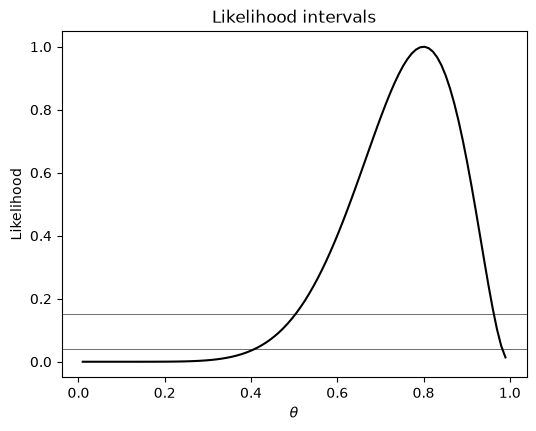

In [11]:
th = np.linspace(0.01, .99, 100)
x = 8
n = 10
like = stats.binom.pmf(x, n, th)
like = like / like.max()

fig, ax = plt.subplots(figsize=(6, 4.5))
ax.plot(th, like, "k-")
for a in [0.04, .15]:
    ax.axhline(a, color="k", lw=0.4)
    print("cutoff=", a, "Interval=", li(th, like, a))

ax.set_xlabel(r"$\theta$")
ax.set_ylabel("Likelihood")
ax.set_title("Likelihood intervals")
plt.show()

## Example 2.15 (`EX2-15.R`)

2.8512512512512513 5.19039039039039


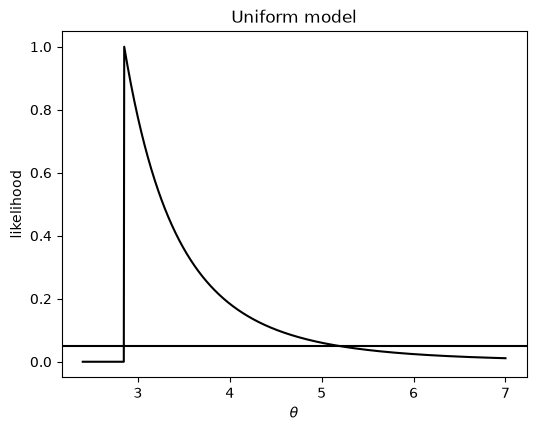

In [12]:
n = 5
x = np.array([2.85, 1.51, 0.69, 0.57, 2.29])
theta = np.linspace(2.4, 7, 1000)

like = np.where(theta > x.max(), theta ** (-n), 0)
like = like / like.max()

a = theta[like > .05]
print(a.min(), a.max())

fig, ax = plt.subplots(figsize=(6, 4.5))
ax.plot(theta, like, "k-")
ax.axhline(.05, color="k")
ax.set_xlabel(r"$\theta$")
ax.set_ylabel("likelihood")
ax.set_title("Uniform model")
plt.show()

## Example 2.16 (`EX2-16.R`)

Censored data.

0.0 0.1393939393939394
0.021212121212121213 0.10303030303030303


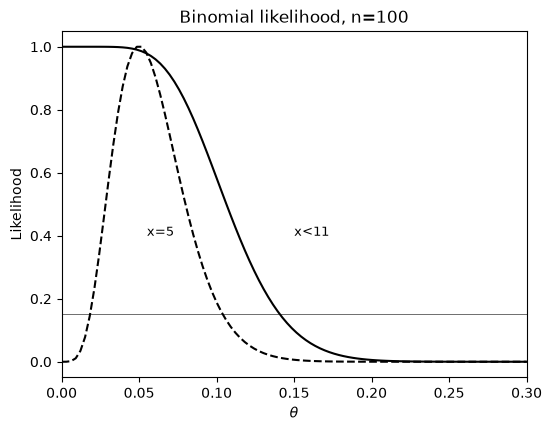

In [13]:
theta = np.linspace(0, .3, 100)
like = stats.binom.cdf(10, 100, theta)
like1 = like / like.max()

a = theta[like1 > .15]
print(a.min(), a.max())

like = stats.binom.pmf(5, 100, theta)
like2 = like / like.max()
b = theta[like2 > .15]
print(b.min(), b.max())

fig, ax = plt.subplots(figsize=(6, 4.5))
ax.plot(theta, like1, "k-")
ax.plot(theta, like2, "k--")
ax.text(.15, .4, "x<11", fontsize=9)
ax.text(.055, .4, "x=5", fontsize=9)
ax.axhline(.15, color="k", lw=0.4)
ax.set_xlim(0, .3)
ax.set_xlabel(r"$\theta$")
ax.set_ylabel("Likelihood")
ax.set_title("Binomial likelihood, n=100")
plt.show()

## Example 2.18 (`EX2-18.R`)

0.5072727272727273 0.9602020202020202


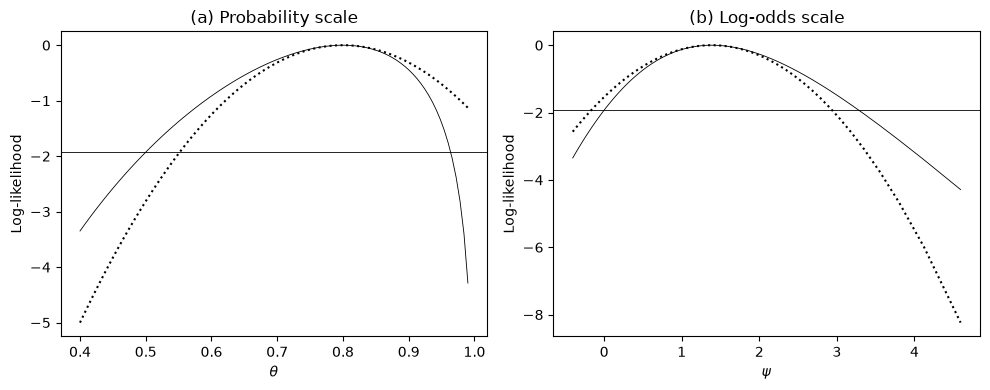

In [14]:
x, n = 8, 10

theta = np.linspace(0.4, .99, 100)
like = stats.binom.pmf(8, 10, theta)
like1 = like / like.max()
ll = np.log(like1)
a = theta[like1 > .15]
print(a.min(), a.max())

that = x / n
ihat = n / that / (1 - that)
la = -ihat / 2 * (theta - that) ** 2

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

ax = axes[0]
ax.plot(theta, ll, "k-", lw=0.6)
ax.plot(theta, la, "k:", lw=1.5)
ax.axhline(-1.92, color="k", lw=0.6)
ax.set_xlabel(r"$\theta$")
ax.set_ylabel("Log-likelihood")
ax.set_title("(a) Probability scale")

psi = np.log(theta) - np.log(1 - theta)
psihat = np.log(that) - np.log(1 - that)
ihat = x * (n - x) / n
lpsi = -ihat / 2 * (psi - psihat) ** 2

ax = axes[1]
ax.plot(psi, ll, "k-", lw=0.6)
ax.plot(psi, lpsi, "k:", lw=1.5)
ax.axhline(-1.92, color="k", lw=0.6)
ax.set_xlabel(r"$\psi$")
ax.set_ylabel("Log-likelihood")
ax.set_title("(b) Log-odds scale")

fig.tight_layout()
plt.show()